Sampling frequency: 44100 Hz
Duration: 218.77 seconds
Number of channels: 2

========== PART A: LOW-PASS FILTERING ==========


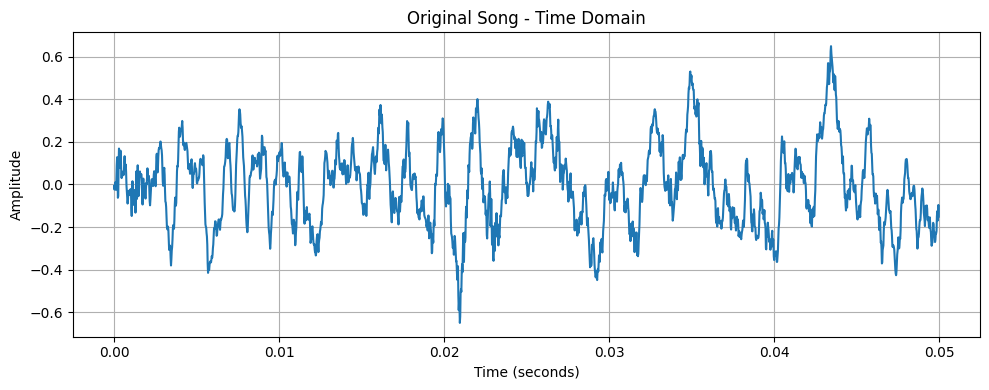

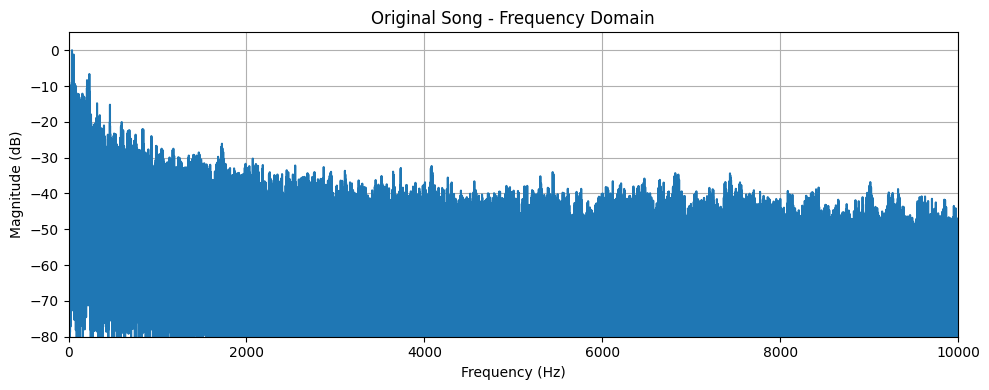

Saved: lowpass_500Hz.mp3


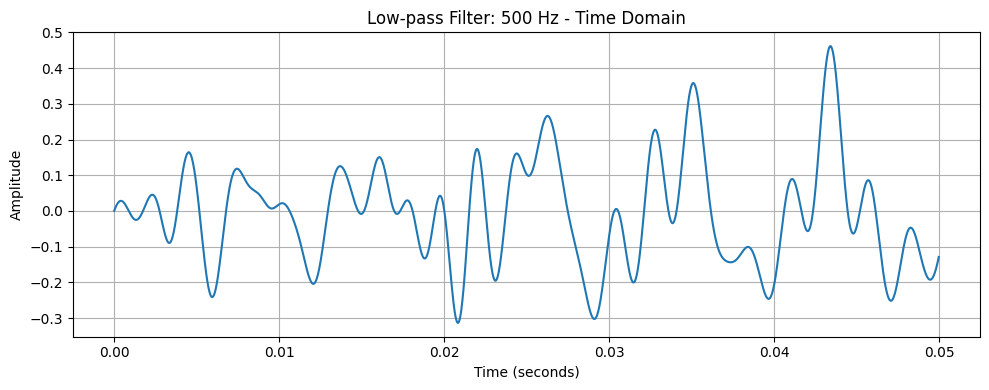

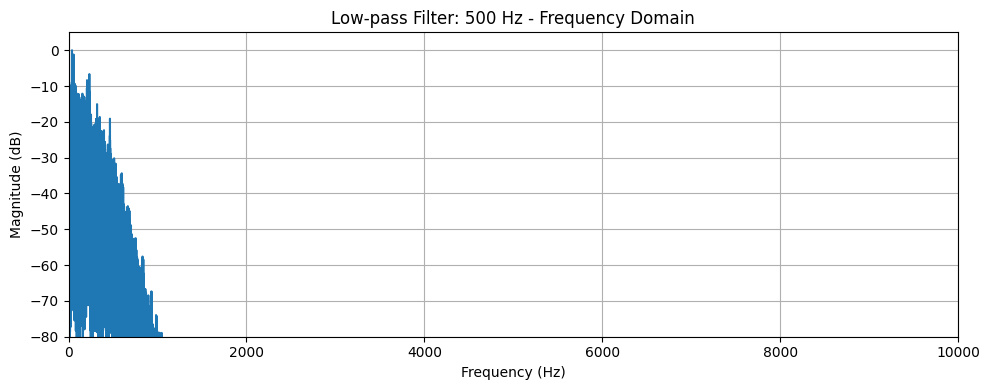

Saved: lowpass_1500Hz.mp3


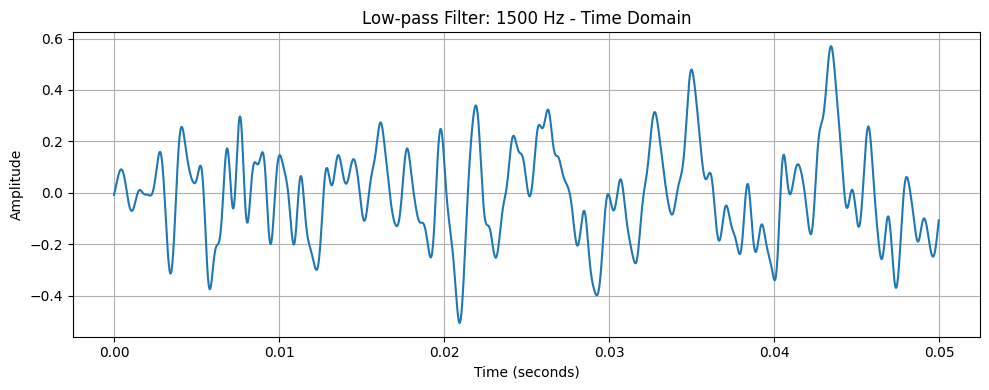

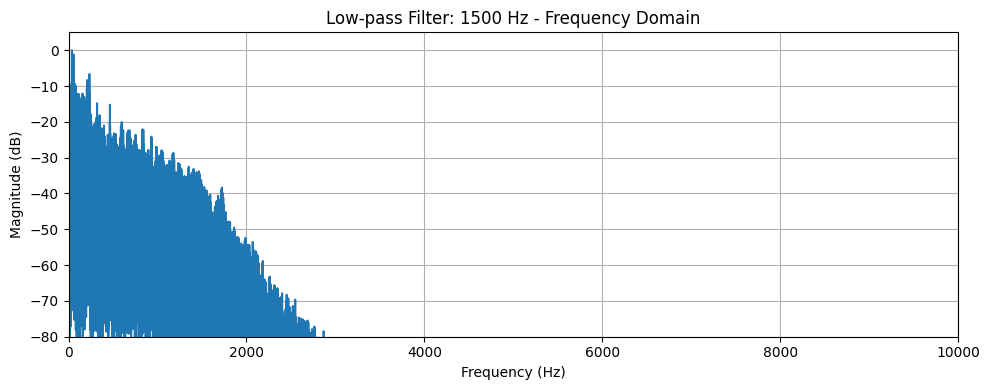

Saved: lowpass_3000Hz.mp3


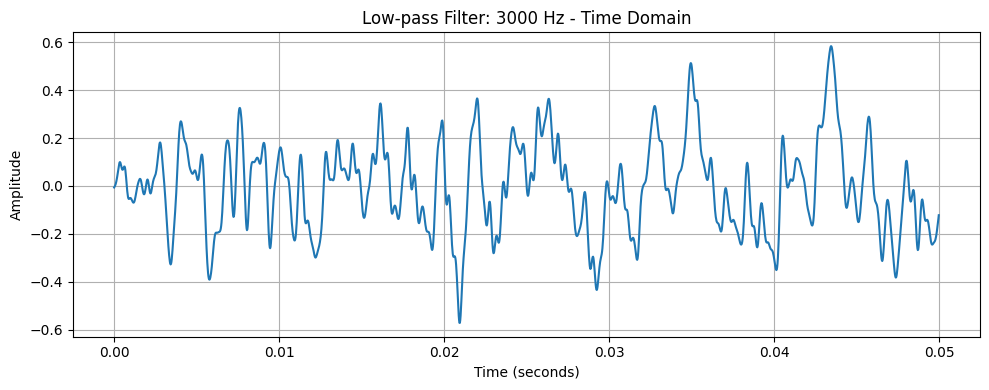

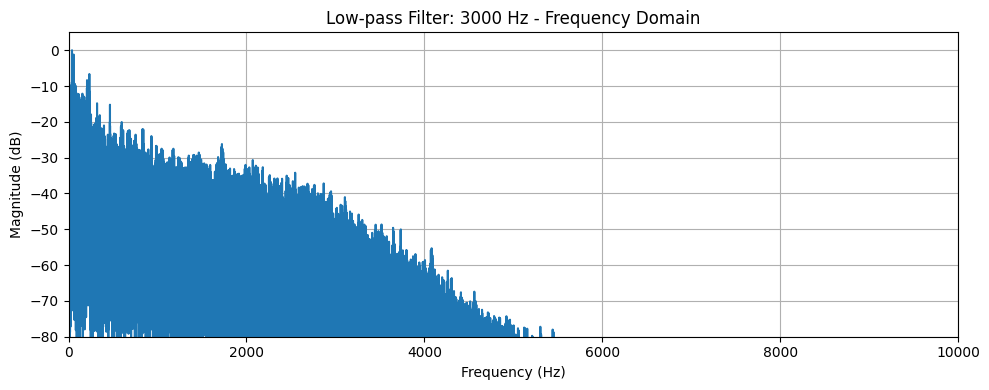


========== PART B: FREQUENCY-BAND FILTERING ==========
Saved: vocal_band.mp3


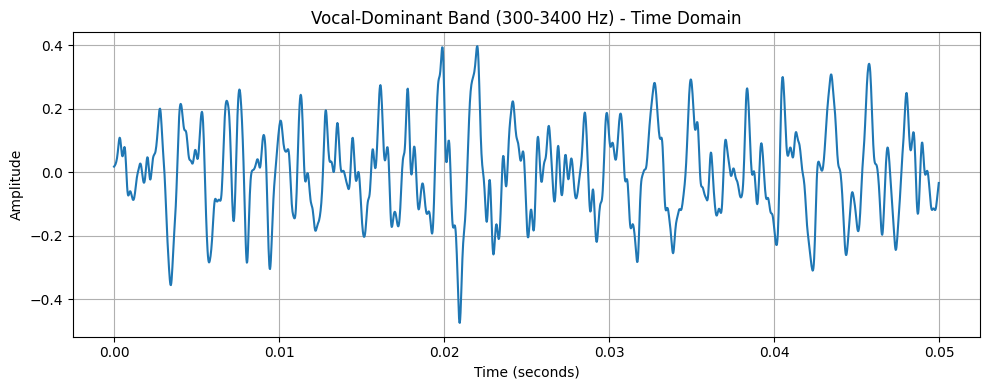

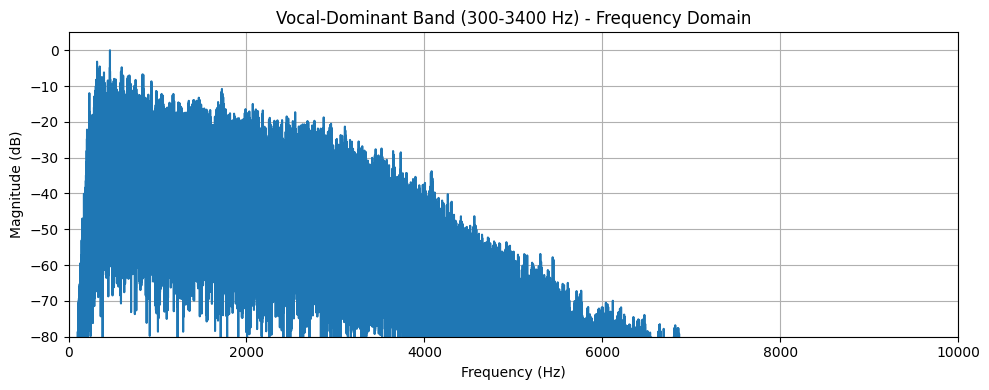

Saved: music_dominant_residual.mp3


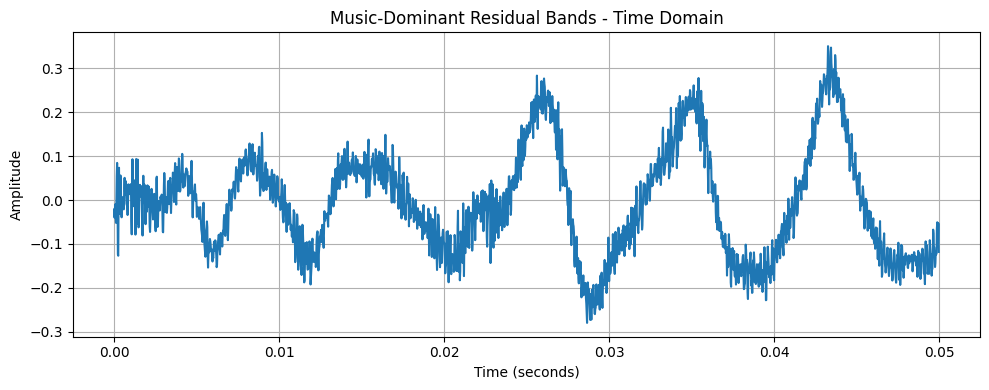

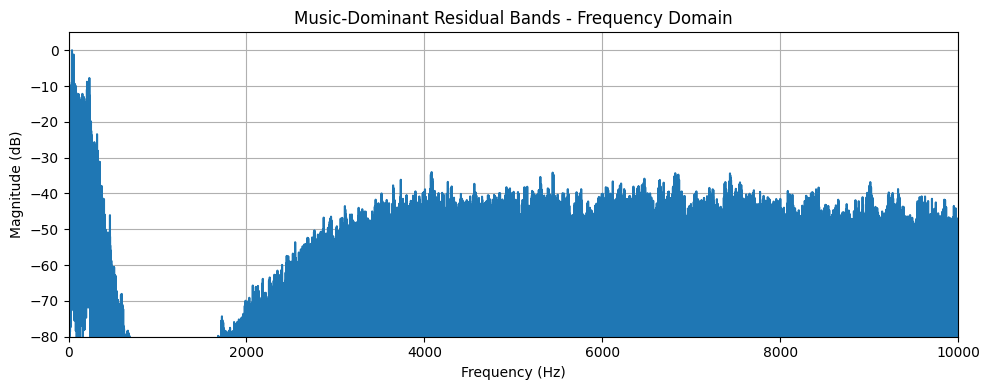

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from pydub import AudioSegment

# --------------------------------------------------
# 1. Load the MP3 song
# --------------------------------------------------
filename = "Boom Shaka - Krsna.mp3"

audio = AudioSegment.from_file(filename, format="mp3")
fs = audio.frame_rate
channels = audio.channels

# Convert audio samples to floating-point values
samples = np.array(audio.get_array_of_samples(), dtype=np.float64)
samples = samples.reshape(-1, channels)

peak_original = np.max(np.abs(samples))
if peak_original > 0:
    samples = samples / peak_original

duration = len(samples) / fs

print("Sampling frequency:", fs, "Hz")
print("Duration:", round(duration, 2), "seconds")
print("Number of channels:", channels)


# --------------------------------------------------
# 2. Helper function to save audio as MP3
# --------------------------------------------------
def save_mp3(data, output_filename):
    data = np.asarray(data, dtype=np.float64)

    # Normalize to prevent clipping
    peak = np.max(np.abs(data))
    if peak > 0:
        data = data / peak * 0.95

    pcm = (data * 32767).astype(np.int16)

    segment = AudioSegment(
        data=pcm.tobytes(),
        sample_width=2,
        frame_rate=fs,
        channels=channels
    )

    segment.export(
        output_filename,
        format="mp3",
        bitrate="192k"
    )

    print("Saved:", output_filename)


# --------------------------------------------------
# 3. Butterworth digital filter function
# --------------------------------------------------
def apply_filter(data, low=None, high=None, order=4):
    nyquist = fs / 2

    if low is not None and high is not None:
        if not (0 < low < high < nyquist):
            raise ValueError(
                f"Invalid band-pass limits: {low}, {high} Hz"
            )

        sos = butter(
            order,
            [low, high],
            btype="bandpass",
            fs=fs,
            output="sos"
        )

    elif high is not None:
        if not (0 < high < nyquist):
            raise ValueError(f"Invalid low-pass cutoff: {high} Hz")

        sos = butter(
            order,
            high,
            btype="lowpass",
            fs=fs,
            output="sos"
        )

    elif low is not None:
        if not (0 < low < nyquist):
            raise ValueError(f"Invalid high-pass cutoff: {low} Hz")

        sos = butter(
            order,
            low,
            btype="highpass",
            fs=fs,
            output="sos"
        )

    else:
        return data.copy()

    return sosfiltfilt(sos, data, axis=0)


# --------------------------------------------------
# 4. Plot waveform and frequency spectrum
# --------------------------------------------------
def plot_audio(data, title):
    # Convert stereo to mono for plotting the spectrum
    mono = data.mean(axis=1)

    # Plot first 0.05 seconds of the waveform
    n = min(len(data), max(1, int(0.05 * fs)))
    time = np.arange(n) / fs

    plt.figure(figsize=(10, 4))
    plt.plot(time, data[:n, 0])
    plt.title(title + " - Time Domain")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot frequency spectrum of the full signal
    spectrum = np.abs(np.fft.rfft(mono))
    frequencies = np.fft.rfftfreq(len(mono), d=1 / fs)

    db = 20 * np.log10(
        spectrum / (spectrum.max() + 1e-12) + 1e-12
    )

    plt.figure(figsize=(10, 4))
    plt.plot(frequencies, db)
    plt.xlim(0, min(10000, fs / 2))
    plt.ylim(-80, 5)
    plt.title(title + " - Frequency Domain")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# PART A: Low-pass filtering with three cutoff values
# --------------------------------------------------
print("\n========== PART A: LOW-PASS FILTERING ==========")

cutoffs = [500, 1500, 3000]

plot_audio(samples, "Original Song")

for cutoff in cutoffs:
    if cutoff >= fs / 2:
        print("Skipping invalid cutoff:", cutoff)
        continue

    filtered = apply_filter(samples, high=cutoff, order=4)

    save_mp3(filtered, f"lowpass_{cutoff}Hz.mp3")
    plot_audio(filtered, f"Low-pass Filter: {cutoff} Hz")


# --------------------------------------------------
# PART B: Vocal-dominant and music-dominant filtering
# --------------------------------------------------
print("\n========== PART B: FREQUENCY-BAND FILTERING ==========")

# Approximate vocal frequency range
vocal_low = 300
vocal_high = min(3400, fs / 2 - 1)

if vocal_high <= vocal_low:
    raise ValueError(
        "Sampling rate is too low for the selected vocal band."
    )

# 1. Band-pass filter: emphasize frequencies from 300 to 3400 Hz
vocal_band = apply_filter(
    samples,
    low=vocal_low,
    high=vocal_high,
    order=4
)

save_mp3(vocal_band, "vocal_band.mp3")
plot_audio(vocal_band, "Vocal-Dominant Band (300-3400 Hz)")


# 2. Estimate music-dominant components
# Low-frequency band: bass and lower musical components
low_music = apply_filter(
    samples,
    high=300,
    order=4
)

# High-frequency band: cymbals, treble and other upper components
if fs / 2 > 3400:
    high_music = apply_filter(
        samples,
        low=3400,
        order=4
    )
else:
    high_music = np.zeros_like(samples)

# Combine low and high frequency components
music_residual = low_music + high_music

save_mp3(music_residual, "music_dominant_residual.mp3")
plot_audio(music_residual, "Music-Dominant Residual Bands")

